# Existing Client Win/Loss by Client

**Questions:** (1) What is the win rate for each client in the Existing Clients Pipeline? (2) Is there a common reason deals fail or succeed for each client?

**Data:** `Existing_Client_Deal_Reasons.csv`, pulled from the Element Three HubSpot portal on 2026-10-20. It covers every Existing Clients Pipeline deal with a close date on or after 2022-01-01 (1,821 deals, 1,781 of them closed). Client = HubSpot's *Associated Company Name*, with a few duplicate spellings merged.

**How to read it:**
- **Win %** = won ÷ closed.
- Many Closed Lost deals weren't lost: they were merged into another deal, moved to T&M, duplicated, or were old placeholders. These are tagged **Admin / restructured** and excluded from the **adjusted win %**, which is the better measure of how often real asks convert.
- *Closed Lost Reason* is free text, so reasons are grouped into categories by keyword rules (shown below). Treat the categories as approximate. Section 6 lists the actual reasons for each client.
- *Closed Won Reason* is mostly just "signed" (118 of 307 filled in, none in 2026). It doesn't explain wins, so Section 4 uses the deal data instead (deal type, size, time open).

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.0f}'.format)
pd.set_option('display.max_colwidth', 120)

MIN_DEALS = 15  # clients with fewer closed deals are too small to compare

CLIENT_ALIASES = {
    'Beckman Coulter Diagnostics': 'Beckman Coulter',
    "Beck's Superior Hybrids, Inc.": 'Becks Hybrids',
    'Grain Processing Company': 'Grain Processing Corporation',
    'Kent': 'Kent Corporation',
    'Great': 'Great Dane',
    'Atlas': 'Atlas Van Lines', 'Atlas World Group': 'Atlas Van Lines',
    'LEGEND': 'Legend',
}

# Loss reason rules, checked in order; first match wins
LOSS_RULES = [
    ('Admin / restructured', r'merg|combin|fold(ing)? into|absorb|wrap|roll(ed)? into|bak(e|ing)|(will be|as|be|getting|now|is) part of|^part of|within|inside|into (a |an |the )?(different|another|other|larger|bigger|existing|new)|t&m|time and material|duplicat|split|break (this|it)|broke|old deal|hygiene|test|redo|placeholder|errant|accidental|restructured deal|condens|new biz|new deal|change order|sow change|reorganizing the work|changing the breakdown|separate deal|other deals|sprint format|fixed fee|placed within|incorporated|covered|covers this|signatures|won this deal|superseded|precedes|replaced|will show up|not a standalone|in sourcing|per project basis|moving amp|pivot amp|deal owner deleted|rfp|included in|addressed in|instead|different shape|output of|^closed$'),
    ('Went quiet / no traction', r'traction|respon|ghost|dark|quiet|dormant|inactiv|silence|momentum|energy|movement|communication|heard back|slow|no update|progress'),
    ('Went with another partner', r'partner|agency|agencies|vendor|freelanc|ibex|did not win|existing contract'),
    ('Client org change', r'reorg|leadership|restructur|new role|champion|departure|gone|pe deal|folding the|leaving|breakup|no longer working|left|hired|hiring|global'),
    ('Doing it in-house', r'in.?house|internal|own(ing)? this|lead strategy|do this for free|on their own'),
    ('Budget', r'budget|fund|money|dollars|cost|expensive|price|financ|invest|pay|freeze|cuts?\b|spend'),
    ('Timing / delayed', r'push|next year|later|delay|postpon|waiting|20(2[2-9])|fy ?2?\d|not this year|this year|not (the )?right time|not ready|timeline|time with|not enough time|nomination window|launch|come back|for now|revisit|q[1-4]|dec\b|eoy|foreseeable'),
    ('No need / not a priority', r"priorit|need|interest|declin|said no|say no|\bno\b$|not doing|won.?t do|relevant|direction|pivot|chang|approach|rationale|demand|applicable|necessary|nice to have|important|abandon|cancel|not happening|not taking|isn.?t happening|off the table|no longer|not committed|not allocating|simplified|didn.?t show|did not show|not a thing|not want|doesn.?t make sense|no role|isn.?t a role|no way for e3|no opportunity|no marketing|unclear|uncertain|decision state"),
    ('Rep judgment: unlikely', r"don.?t (think|expect|believe|have any)|calling it|unlikely|never|long shot|not a real|isn.?t a real|feels|possible but|maybe|no indication"),
]

def loss_category(reason):
    if pd.isna(reason) or not str(reason).strip():
        return 'No reason given'
    r = str(reason).lower()
    for cat, pat in LOSS_RULES:
        if re.search(pat, r):
            return cat
    return 'Other / unclear'

def deal_kind(name):
    n = str(name).lower()
    if re.search(r'change order|\bco\b|increase|expansion|additional|add-on|addendum', n):
        return 'Change order / expansion'
    if re.search(r'annual|renewal|retainer|recurring|ongoing|monthly|general support|\bfy ?\d\d|\bmy ?\d\d|20\d\d|q[1-4]\b|h[12]\b|management|mgmt|support', n):
        return 'Recurring / planned'
    return 'One-off project'

In [2]:
d = pd.read_csv('Existing_Client_Deal_Reasons.csv')
for c in ['Create Date', 'Close Date']:
    d[c] = pd.to_datetime(d[c], format='ISO8601', utc=True)
d['Client'] = d['Company'].fillna('(no company)').str.strip().replace(CLIENT_ALIASES)
d['Amount'] = d['Amount'].fillna(0)
d['Close Year'] = d['Close Date'].dt.year
d['Status'] = np.where(d['Deal Stage'] == '100% Closed Won', 'Won',
              np.where(d['Deal Stage'] == 'Closed Lost', 'Lost', 'Open'))
d['Won'] = d['Status'] == 'Won'
d['Outcome'] = np.where(d['Won'], 'Won', d['Closed Lost Reason'].map(loss_category))
d['Admin'] = d['Outcome'] == 'Admin / restructured'
d['Deal Kind'] = d['Deal Name'].map(deal_kind)
d['Days Open'] = (d['Close Date'] - d['Create Date']).dt.days

closed = d[d['Status'] != 'Open'].copy()
real = closed[~closed['Admin']].copy()  # admin closures removed
print(f"Closed deals: {len(closed):,}  |  won {closed['Won'].sum():,}  |  lost {(~closed['Won']).sum():,}")
print(f"Admin / restructured closures: {closed['Admin'].sum():,} ({closed['Admin'].sum() / (~closed['Won']).sum():.0%} of all losses)")
print(f"Win rate: raw {closed['Won'].mean():.0%}  ->  adjusted {real['Won'].mean():.0%}")

Closed deals: 1,781  |  won 1,023  |  lost 758
Admin / restructured closures: 147 (19% of all losses)
Win rate: raw 57%  ->  adjusted 63%


## 1. Loss reasons overall

In [3]:
lost = closed[~closed['Won']]
lr = lost['Outcome'].value_counts().to_frame('Deals')
lr['% of losses'] = lr['Deals'] / lr['Deals'].sum() * 100
lr['% of losses with a reason'] = lr['Deals'] / lr.drop('No reason given', errors='ignore')['Deals'].sum() * 100
lr.loc['No reason given', '% of losses with a reason'] = np.nan
lr

,Deals,% of losses,% of losses with a reason
Outcome,,,
No reason given,239,32,NaN
Admin / restructured,147,19,28
No need / not a priority,104,14,20
Budget,52,7,10
Timing / delayed,49,6,9
Doing it in-house,43,6,8
Went quiet / no traction,37,5,7
Client org change,34,4,7
Other / unclear,21,3,4


## 2. Win rate by client

Clients with at least 15 closed deals since 2022, sorted by number of closed deals. **Recurring** includes recurring/planned work and change orders; **one-off** is a standalone project ask.

In [4]:
def client_row(x):
    xr = x[~x['Admin']]
    rl = xr[~xr['Won']]
    reasons = rl['Outcome'][rl['Outcome'] != 'No reason given'].value_counts()
    one = xr[xr['Deal Kind'] == 'One-off project']
    rec = xr[xr['Deal Kind'] != 'One-off project']
    recent = xr[xr['Close Year'] >= 2024]
    return pd.Series({
        'Closed': len(x), 'Won': x['Won'].sum(),
        'Win %': x['Won'].mean() * 100,
        'Admin closures': x['Admin'].sum(),
        'Adj. win %': xr['Won'].mean() * 100,
        'Adj. win % 2024-26': recent['Won'].mean() * 100 if len(recent) >= 5 else np.nan,
        'Real losses': len(rl),
        '% losses w/o reason': (rl['Outcome'] == 'No reason given').mean() * 100 if len(rl) else np.nan,
        'Top loss reasons': ', '.join(f'{k} ({v})' for k, v in reasons.head(2).items()),
        'One-off win %': one['Won'].mean() * 100 if len(one) >= 3 else np.nan,
        'One-off n': len(one),
        'Recurring win %': rec['Won'].mean() * 100 if len(rec) >= 3 else np.nan,
        'Recurring n': len(rec),
        'Won $': x.loc[x['Won'], 'Amount'].sum(),
    })

counts = closed['Client'].value_counts()
big = counts[counts >= MIN_DEALS].index
by_client = closed[closed['Client'].isin(big)].groupby('Client').apply(client_row).sort_values('Closed', ascending=False)
by_client.style.format({'Closed': '{:,.0f}', 'Won': '{:,.0f}', 'Admin closures': '{:,.0f}', 'Real losses': '{:,.0f}',
                        'One-off n': '{:,.0f}', 'Recurring n': '{:,.0f}', 'Won $': '${:,.0f}',
                        'Win %': '{:.0f}%', 'Adj. win %': '{:.0f}%', 'Adj. win % 2024-26': '{:.0f}%',
                        '% losses w/o reason': '{:.0f}%', 'One-off win %': '{:.0f}%', 'Recurring win %': '{:.0f}%'}, na_rep='–')

/var/folders/09/2rl5v52n3qx74l2pc1t00xvc0000gq/T/ipykernel_96616/2388436680.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_client = closed[closed['Client'].isin(big)].groupby('Client').apply(client_row).sort_values('Closed', ascending=False)


,Closed,Won,Win %,Admin closures,Adj. win %,Adj. win % 2024-26,Real losses,% losses w/o reason,Top loss reasons,One-off win %,One-off n,Recurring win %,Recurring n,Won $
Client,,,,,,,,,,,,,,
Newmar Corporation,283,219,77%,16,82%,83%,48,27%,"Went quiet / no traction (9), Budget (7)",64%,95,92%,172,"$6,624,632"
Airstream,227,132,58%,22,64%,59%,73,64%,"No need / not a priority (7), Doing it in-house (6)",50%,126,87%,79,"$4,998,640"
Model 1,151,84,56%,19,64%,55%,48,38%,"No need / not a priority (19), Went quiet / no traction (3)",56%,84,77%,48,"$3,214,000"
Becks Hybrids,81,38,47%,6,51%,42%,37,49%,"Went quiet / no traction (4), Doing it in-house (4)",41%,49,69%,26,"$1,649,050"
Road Ready,59,54,92%,1,93%,88%,4,100%,,98%,40,83%,18,"$812,518"
REV Group,59,37,63%,6,70%,70%,16,0%,"No need / not a priority (11), Timing / delayed (2)",67%,33,75%,20,"$1,850,200"
Grain Processing Corporation,50,40,80%,5,89%,89%,5,60%,"Doing it in-house (1), Timing / delayed (1)",82%,22,96%,23,"$1,553,950"
CleanSlate,48,30,62%,6,71%,62%,12,17%,"No need / not a priority (4), Timing / delayed (3)",68%,22,75%,20,"$503,750"
Premium Audio Company,44,19,43%,10,56%,56%,15,33%,"Budget (4), Timing / delayed (3)",67%,21,38%,13,"$281,100"


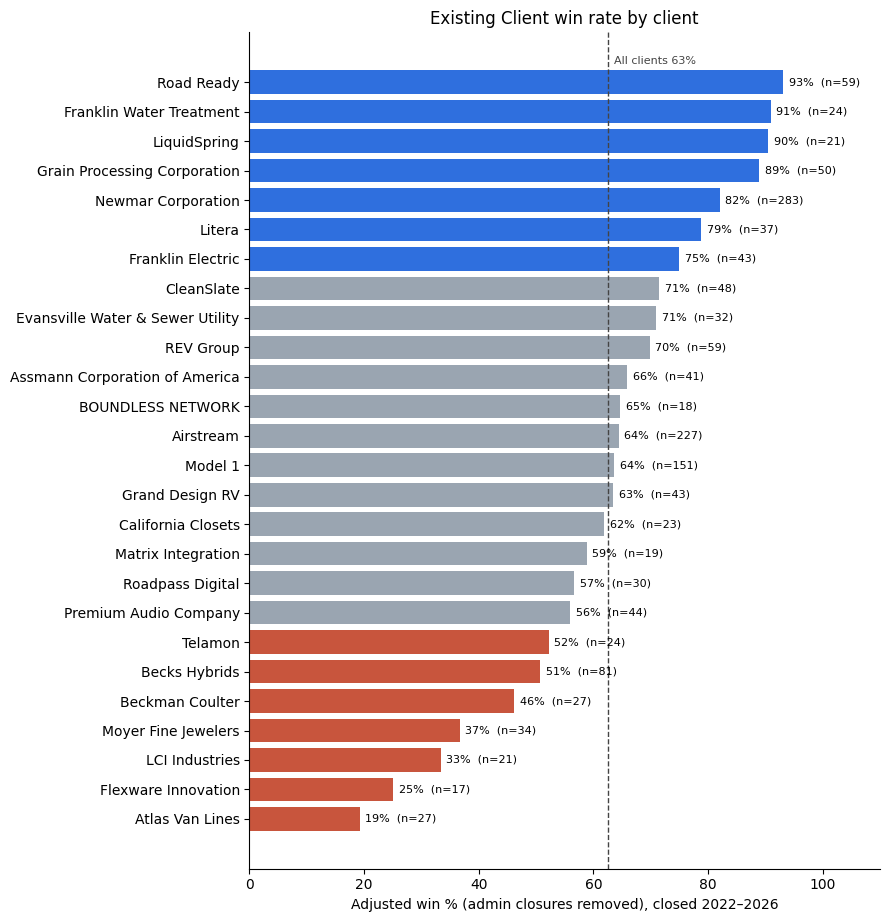

In [5]:
avg = real['Won'].mean() * 100
t = by_client.sort_values('Adj. win %')
fig, ax = plt.subplots(figsize=(9, 0.32 * len(t) + 1))
colors = ['#C8553D' if v < avg - 10 else '#2F6FDE' if v > avg + 10 else '#9AA5B1' for v in t['Adj. win %']]
ax.barh(t.index, t['Adj. win %'], color=colors)
for i, (v, n) in enumerate(zip(t['Adj. win %'], t['Closed'])):
    ax.text(v + 1, i, f'{v:.0f}%  (n={n:.0f})', va='center', fontsize=8)
ax.axvline(avg, color='#444', ls='--', lw=1)
ax.text(avg + 1, len(t) - 0.4, f'All clients {avg:.0f}%', fontsize=8, color='#444')
ax.set_xlim(0, 110); ax.set_xlabel('Adjusted win % (admin closures removed), closed 2022–2026')
ax.set_title('Existing Client win rate by client')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 3. Loss reasons by client

Count of real losses (admin closures removed) by reason category.

In [6]:
cats_order = [c for c in lr.index if c not in ('Admin / restructured',)]
mix = (closed[closed['Client'].isin(big) & ~closed['Won'] & ~closed['Admin']]
       .pivot_table(index='Client', columns='Outcome', values='Record ID', aggfunc='count', fill_value=0)
       .reindex(columns=[c for c in cats_order if c in closed['Outcome'].unique()], fill_value=0))
mix = mix.loc[by_client.index]
mix.style.background_gradient(cmap='Reds', axis=1).format('{:.0f}')

Outcome,No reason given,No need / not a priority,Budget,Timing / delayed,Doing it in-house,Went quiet / no traction,Client org change,Other / unclear,Rep judgment: unlikely,Went with another partner
Client,,,,,,,,,,
Newmar Corporation,13,7,7,3,3,9,2,1,1,2
Airstream,47,7,3,4,6,2,0,3,0,1
Model 1,18,19,3,2,1,3,0,1,0,1
Becks Hybrids,18,3,4,1,4,4,0,3,0,0
Road Ready,4,0,0,0,0,0,0,0,0,0
REV Group,0,11,0,2,1,0,1,1,0,0
Grain Processing Corporation,3,0,0,1,1,0,0,0,0,0
CleanSlate,2,4,0,3,1,0,0,1,1,0
Premium Audio Company,5,0,4,3,1,0,0,1,0,1


## 4. What predicts a win?

*Closed Won Reason* doesn't help (mostly "signed"), so this uses the deal data instead. Admin closures are removed.

In [7]:
def rate(col):
    g = real.groupby(col, observed=True)['Won'].agg(Deals='size', Win_pct='mean')
    g['Win_pct'] *= 100
    return g.rename(columns={'Win_pct': 'Win %'})

print('By deal type (from deal name)'); display(rate('Deal Kind'))
real['Size'] = pd.cut(real['Amount'], [-1, 10_000, 25_000, 50_000, 100_000, 1e9], labels=['≤$10k', '$10–25k', '$25–50k', '$50–100k', '$100k+'])
print('By deal size'); display(rate('Size'))
real['Time open'] = pd.cut(real['Days Open'], [-1, 7, 30, 90, 180, 1e5], labels=['≤1 week', '1–4 weeks', '1–3 months', '3–6 months', '6+ months'])
print('By time from creation to close'); display(rate('Time open'))

By deal type (from deal name)


,Deals,Win %
Deal Kind,,
Change order / expansion,163,87
One-off project,951,52
Recurring / planned,520,75


By deal size


,Deals,Win %
Size,,
≤$10k,630,69
$10–25k,413,51
$25–50k,324,58
$50–100k,190,68
$100k+,77,75


By time from creation to close


,Deals,Win %
Time open,,
≤1 week,287,91
1–4 weeks,379,73
1–3 months,504,57
3–6 months,310,40
6+ months,149,46


- **Deal type is the clearest signal.** Change orders/expansions and recurring/planned work convert far better than one-off project asks.
- **Size matters little:** small and large deals both convert well; the $10–50k middle converts worst.
- **Time open is partly circular.** Wins get closed when signed; losses often sit open until a pipeline cleanup. Still, a deal open 3+ months is closer to a coin flip than a likely win.

## 5. Win rate by year (all clients)

In [8]:
yr = closed.groupby('Close Year').apply(lambda x: pd.Series({
    'Closed': len(x), 'Win %': x['Won'].mean() * 100,
    'Adj. win %': x.loc[~x['Admin'], 'Won'].mean() * 100,
    'Admin closures': x['Admin'].sum(),
    '% losses w/ reason': x.loc[~x['Won'], 'Closed Lost Reason'].notna().mean() * 100}))
yr

/var/folders/09/2rl5v52n3qx74l2pc1t00xvc0000gq/T/ipykernel_96616/2436733367.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  yr = closed.groupby('Close Year').apply(lambda x: pd.Series({


,Closed,Win %,Adj. win %,Admin closures,% losses w/ reason
Close Year,,,,,
2022,344,61,64,13,65
2023,388,61,68,44,76
2024,344,61,66,23,61
2025,382,53,59,42,66
2026,323,51,55,25,74


## 6. Reason detail by client

Every real loss with a recorded reason, for the clients above. Use `show_client('Name')` for any other client.

In [9]:
def show_client(name):
    x = closed[(closed['Client'] == name) & ~closed['Won'] & ~closed['Admin']]
    x = x[x['Outcome'] != 'No reason given'].sort_values('Close Date')
    out = x[['Close Date', 'Deal Name', 'Amount', 'Outcome', 'Closed Lost Reason']].copy()
    out['Close Date'] = out['Close Date'].dt.date
    out['Closed Lost Reason'] = out['Closed Lost Reason'].str.replace(r'\s+', ' ', regex=True).str.slice(0, 160)
    return out

for c in by_client.index:
    t = show_client(c)
    print(f"\n=== {c}: {len(t)} real losses with a reason ===")
    if len(t):
        display(t.style.hide(axis='index').format({'Amount': '${:,.0f}'}))


=== Newmar Corporation: 35 real losses with a reason ===


Close Date,Deal Name,Amount,Outcome,Closed Lost Reason
2023-01-18,NEW: NewServ Promotion (Jan.-Mar. '23),"$8,700",Budget,Jordan deemed this is too expensive for what we are wanting to accomplish.
2023-01-18,NEW: Aimbase Contact Management,"$45,000",No need / not a priority,This capability will likely be built in Salesforce Sales Cloud as opposed to Aimbase and the role Element Three would play is unclear at this point in time.
2023-01-18,NEW: FY23 Tier 1 Owner Story #2,"$58,000",Budget,The available budget with Newmar's annual management plan to fund future owner stories is unclear at this point in time.
2023-01-18,NEW: FY23 Tier 2 Owner Story #2,"$29,000",Budget,The available budget with Newmar's annual management plan to fund future owner stories is unclear at this point in time.
2023-02-06,NEW: FY23 Tier 2 Owner Story #1,"$29,000",Budget,"There is no room in the annual fiscal year marketing budget for Newmar to fund a project like this, nor belief in the need to do this alongside a tier 1 owner s"
2023-03-06,NEW: Dealer Books Digitization,"$9,750",Timing / delayed,Newmar declined to do this for the 2023 Dealer Meeting (April 2023) but wants to keep it on the marketing roadmap as a possibility for future dealer meetings.
2023-04-17,NEW: Consumer Insights Ecosystem,"$50,000",Went quiet / no traction,"There has been no traction on this since it was first discussed on Wednesday, January 11."
2023-04-17,NEW: AVM/LTV Data Analysis - Phase 1,"$20,000",Went quiet / no traction,"There has been no traction on this since the proposal was presented on Monday, December 12, 2022, and the material was briefly revisited during the ""E3-Newmar-W"
2023-04-17,NEW: AVM/LTV Data Proof of Concept - Phase 2,"$45,000",Went quiet / no traction,"There has been no traction on this since the proposal was presented on Monday, December 12, 2022, and the material was briefly revisited during the ""E3-Newmar-W"
2023-04-17,NEW: AVM/LTV Data Implementation - Phase 3,"$70,000",Went quiet / no traction,"There has been no traction on this since the proposal was presented on Monday, December 12, 2022, and the material was briefly revisited during the ""E3-Newmar-W"



=== Airstream: 26 real losses with a reason ===


Close Date,Deal Name,Amount,Outcome,Closed Lost Reason
2022-06-07,AIR: TC Comparison Shoot,"$10,000",Timing / delayed,next year
2022-06-15,AIR: Database Re-engagement,"$22,000",Doing it in-house,Client decided it's too costly and will complete internally
2022-06-28,"AIR: Lead Conversion Evolution (MQL, SQL, + Lead Scoring)","$15,000",Budget,Price was too high - explained that this full project (not just this portion) would probably be in the 250k+ range to do right
2022-09-06,AIR: Lead Nurturing Email Workflow Revamp,"$3,000",Doing it in-house,Airstream doing internally
2022-09-07,AIR: SEO Execution (3 mo),"$18,000",Timing / delayed,Client delayed project for up to a year so I'm killing
2022-09-07,AIR: Content Strategy,"$10,000",Timing / delayed,Client delaying project for new site launch (a year away)
2023-07-24,AIR: Basecamp 20 Product Launch Support,"$3,000",No need / not a priority,no support needed
2023-10-10,AIR: Time to Close by Model Analysis,"$12,000",No need / not a priority,Client did not show interest
2023-11-16,AIR: GTM Shopify Updates,"$3,000",No need / not a priority,no longer needed
2023-12-04,AIR: Lead Scoring,"$20,000",Timing / delayed,client pushed project to 2024



=== Model 1: 30 real losses with a reason ===


...

Close Date,Deal Name,Amount,Outcome,Closed Lost Reason
2024-08-27,MXI - Website Phase 2,"$45,000",Rep judgment: unlikely,I don't expect this to happen
2024-10-09,MXI - New Logo,"$18,000",No need / not a priority,not a priority for the organization



=== BOUNDLESS NETWORK: 5 real losses with a reason ===


Close Date,Deal Name,Amount,Outcome,Closed Lost Reason
2022-07-07,BND: Industry Pillar Content Creation,"$67,500",Other / unclear,Adjusted strategy from building foundational content to building content around initiatives
2022-09-19,BND: Sales Partner Marketing Programs,"$17,500",Timing / delayed,Client has delayed program indefinitely
2022-09-19,BND: Sales Partner Asset and Program Execution,"$20,000",Timing / delayed,Part 2 of a delayed project
2023-01-26,BND2300 Boundless Strategic Operations,"$24,000",Timing / delayed,Not ready for this
2023-04-18,BND Boundless Netsuite-Hubspot Integration,"$10,000",Went quiet / no traction,Client unresponsive



=== Flexware Innovation: 5 real losses with a reason ===


Close Date,Deal Name,Amount,Outcome,Closed Lost Reason
2023-08-01,FLX: Brand Positioning and Messaging,"$100,000",Timing / delayed,not in FY 23-24
2023-08-01,FLX: Value Proposition Development,"$75,000",Timing / delayed,not in FY 23-24
2023-12-04,FLX: 2024,"$45,000",Went quiet / no traction,Closing out AP for 2024 due to lack of communication from the client
2026-06-23,FLX - Content Marketing,"$20,000",Doing it in-house,Handling In-House
2026-06-23,FLX - HubSpot Marketing Hub Implementation,"$15,000",Went with another partner,Not partnering with HubSpot


## Takeaways

**Across all clients**
- About **1 in 5 "losses" are pipeline admin**, not lost work (merged, moved to T&M, duplicates, old placeholders). Removing them lifts the win rate from **57% to about 63%**. If those deals are closed as lost, the conversion rate looks lower than it really is. A separate "Restructured" closed stage or loss reason would keep the numbers clean.
- The most common *real* reasons for losing a deal are **no need / not a priority**, **budget**, **timing/delayed**, and **client doing it in-house**. Losing to another agency is rare (about 2% of losses).
- **What wins:** recurring and planned work (about 75%) and change orders/expansions (about 87%). One-off project ideas win only about **52%**. Most losses are add-on ideas E3 pitched that the client didn't prioritize.
- **Win rates are slipping:** the adjusted rate was 64–68% in 2022–24, 59% in 2025 and 55% in 2026.
- **32% of losses have no reason recorded.** Won reasons were recorded for 51% of wins in 2022 and none in 2026.

**By client** (adjusted win %, closed 2022–26)

| Client | Win % | Pattern |
|---|---|---|
| Newmar (283 deals) | 82% | Annual/recurring work almost always renews (92%). Losses are mostly speculative data, research and tech proposals beyond the annual plan, which stalled ("no traction since the proposal was presented") or hit FY24's no-incremental-budget rule. Newmar also took some work in-house after hiring. |
| Airstream (227) | 64% | Recurring work converts at 87%, one-off asks at 50%. Real losses: the client did it internally (lead nurture, Aimbase consulting, database re-engagement), not needed, or delayed (SEO, content strategy). Many small ALIGN+ dealer deals fall through, for example dealers who ghost or won't use two agencies. |
| Model 1 (151) | 64% | The most "not interested / not a priority" losses of any client (19). Many are idea-stage placeholder deals (MO25##, MO26XX) that were never confirmed asks. Recent rate is 55%. |
| Becks Hybrids (81) | 51% | Falling: 42% in 2024–26. Losses are budget constraints, the client handling work in-house, and stalled CRM-phase deals that were pitched ahead of a decision. Half the losses have no reason recorded. |
| REV Group (59) | 70% | Almost all losses are "not a priority / no need" on pitched add-ons (AI, SEO audit, brand architecture). Reasons are recorded on every loss. |
| Road Ready, LiquidSpring, Grain Processing, Franklin Water | 89–93% | Near-automatic conversion: mostly small, planned asks. |
| Premium Audio (44) | 56% | Losses are budget cuts and media cuts. Unusually, recurring work converts *worse* (38%) than one-offs. |
| Grand Design (43) | 63% | One-off asks win only 20%, recurring 88%. Losses: no budget, and the client paying for media directly to avoid the 5% fee. |
| Atlas Van Lines (27) | 19% | Lowest. A 2026 reorg ("reorg/different direction", leadership change) killed a run of planned quarterly deals. Earlier losses were budget and going with another partner. |
| LCI Industries (21) | 33% | Brand projects declined, and the Duncan business was folded. |
| Moyer Fine Jewelers (34) | 37% | No loss reasons recorded at all, so there's no pattern to report. |

**Caveats**
- Reason categories come from keyword rules on free text. They're approximate; Section 6 has the actual reasons.
- "Client" relies on HubSpot's Associated Company Name. I merged a few duplicate spellings, but sub-brands such as Franklin Electric vs. Franklin Water Treatment are kept separate.
- Deal type comes from keywords in the deal name, so some deals will be mislabeled.

## 7. Industry breakdown

Industry is HubSpot's company **Industry** field, pulled 2026-10-23 into `Company_Industry.csv` and matched to each deal's client. HubSpot's labels are used as they are, with these known problems:
- **Automotive** covers RV makers (Newmar, Airstream, REV, Grand Design, Thor), commercial vehicles (Model 1, PACCAR, Great Dane), suppliers (Allison) and auto services (Jiffy Lube, Mister Car Wash). It's 46% of closed deals.
- Some labels look wrong: Roche is Construction, BoatUS is Political Organization, Beck's Hybrids (seed) is Food & Beverages, Road Ready is Computer Software, Atlas World Group is Capital Markets. Fixing these in HubSpot would improve the breakdown.
- Industries with fewer than 20 closed deals are grouped as **Other industries**.

Open pipeline uses `Existing_Client_Open_Deals_2026-10-23.csv` (101 deals, pulled 2026-10-23). It's newer than the 91-deal snapshot in Stage_Conversion_Accuracy.ipynb.

In [10]:
ind = pd.read_csv('Company_Industry.csv')
ind['key'] = ind['Company'].str.strip().str.lower()
ind_map = dict(zip(ind['key'], ind['Industry']))

LABELS = {'AUTOMOTIVE': 'Automotive', 'COMPUTER_SOFTWARE': 'Computer Software',
          'MECHANICAL_OR_INDUSTRIAL_ENGINEERING': 'Industrial Engineering', 'FOOD_BEVERAGES': 'Food & Beverages',
          'FOOD_PRODUCTION': 'Food Production', 'CONSTRUCTION': 'Construction', 'APPAREL_FASHION': 'Apparel & Fashion',
          'RETAIL': 'Retail', 'TRANSPORTATION_TRUCKING_RAILROAD': 'Transportation/Trucking', 'MARITIME': 'Maritime',
          'TELECOMMUNICATIONS': 'Telecommunications', 'INFORMATION_TECHNOLOGY_AND_SERVICES': 'IT Services',
          'HOSPITAL_HEALTH_CARE': 'Hospital & Health Care', 'POLITICAL_ORGANIZATION': 'Political Organization',
          'CHEMICALS': 'Chemicals'}

def industry_of(client, company):
    for name in (client, company):
        v = ind_map.get(str(name).strip().lower())
        if isinstance(v, str) and v:
            return LABELS.get(v, v.replace('_', ' ').title())
    return 'Not set in HubSpot'

for df in (d, closed, real):
    df['Industry'] = [industry_of(c, co) for c, co in zip(df['Client'], df['Company'])]

big_ind = closed['Industry'].value_counts()
keep = big_ind[(big_ind >= 20)].index
def bucket(i):
    return i if i in keep or i == 'Not set in HubSpot' else 'Other industries'
for df in (d, closed, real):
    df['Industry group'] = df['Industry'].map(bucket)
print('Deals with an industry:', f"{(closed['Industry'] != 'Not set in HubSpot').mean():.0%}")

Deals with an industry: 86%


In [11]:
def industry_row(x):
    xr = x[~x['Admin']]
    rl = xr[~xr['Won']]
    reasons = rl['Outcome'][rl['Outcome'] != 'No reason given'].value_counts()
    rec = xr[xr['Deal Kind'] != 'One-off project']; one = xr[xr['Deal Kind'] == 'One-off project']
    recent = xr[xr['Close Year'] >= 2024]
    return pd.Series({
        'Clients': x['Client'].nunique(), 'Closed': len(x),
        'Adj. win %': xr['Won'].mean() * 100,
        'Adj. win % 2024-26': recent['Won'].mean() * 100 if len(recent) >= 5 else np.nan,
        'Recurring win %': rec['Won'].mean() * 100 if len(rec) >= 3 else np.nan,
        'One-off win %': one['Won'].mean() * 100 if len(one) >= 3 else np.nan,
        'Top loss reasons': ', '.join(f'{k} ({v})' for k, v in reasons.head(2).items()),
        'Won $': x.loc[x['Won'], 'Amount'].sum(),
        'Largest clients': ', '.join(x['Client'].value_counts().head(3).index),
    })

by_ind = closed.groupby('Industry group').apply(industry_row).sort_values('Closed', ascending=False)
by_ind.style.format({'Clients': '{:,.0f}', 'Closed': '{:,.0f}', 'Won $': '${:,.0f}', 'Adj. win %': '{:.0f}%',
                     'Adj. win % 2024-26': '{:.0f}%', 'Recurring win %': '{:.0f}%', 'One-off win %': '{:.0f}%'}, na_rep='–')

/var/folders/09/2rl5v52n3qx74l2pc1t00xvc0000gq/T/ipykernel_96616/532559992.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_ind = closed.groupby('Industry group').apply(industry_row).sort_values('Closed', ascending=False)


,Clients,Closed,Adj. win %,Adj. win % 2024-26,Recurring win %,One-off win %,Top loss reasons,Won $,Largest clients
Industry group,,,,,,,,,
Automotive,17,823,69%,65%,86%,53%,"No need / not a priority (57), Budget (19)","$18,622,222","Newmar Corporation, Airstream, Model 1"
Not set in HubSpot,17,250,60%,59%,72%,53%,"No need / not a priority (19), Client org change (12)","$3,649,150","CleanSlate, Premium Audio Company, Roadpass Digital"
Computer Software,6,122,76%,82%,76%,76%,"No need / not a priority (5), Doing it in-house (3)","$2,369,568","Road Ready, Litera, Flexware Innovation"
Industrial Engineering,3,86,68%,52%,80%,61%,"No need / not a priority (5), Went quiet / no traction (3)","$1,574,900","Franklin Electric, Assmann Corporation of America, Kem Krest LLC"
Food & Beverages,2,85,49%,40%,70%,38%,"Went quiet / no traction (4), Doing it in-house (4)","$1,652,050","Becks Hybrids, Kent Corporation"
Other industries,15,83,29%,22%,35%,27%,"Budget (6), Timing / delayed (5)","$478,200","Duramark, Neoti, Polygon Composites"
Construction,5,51,54%,56%,64%,46%,"Doing it in-house (4), Client org change (3)","$830,000","Evansville Water & Sewer Utility, Roche, River Pools"
Food Production,1,50,89%,89%,96%,82%,"Doing it in-house (1), Timing / delayed (1)","$1,553,950",Grain Processing Corporation
Apparel & Fashion,2,47,33%,33%,55%,25%,"Timing / delayed (4), Other / unclear (2)","$231,800","Moyer Fine Jewelers, Wildman"


In [12]:
yr_ind = (real[real['Close Year'] >= 2022].pivot_table(index='Industry group', columns='Close Year', values='Won', aggfunc='mean') * 100)
yr_n = real[real['Close Year'] >= 2022].pivot_table(index='Industry group', columns='Close Year', values='Won', aggfunc='size')
yr_ind = yr_ind.where(yr_n >= 5)  # hide years with fewer than 5 closed deals
yr_ind.loc[by_ind.index].style.format('{:.0f}%', na_rep='–').background_gradient(cmap='RdYlGn', vmin=20, vmax=95, axis=None)

Close Year,2022,2023,2024,2025,2026
Industry group,,,,,
Automotive,83%,71%,66%,67%,62%
Not set in HubSpot,52%,73%,67%,51%,63%
Computer Software,60%,76%,87%,80%,50%
Industrial Engineering,71%,83%,73%,42%,–
Food & Beverages,–,70%,68%,20%,14%
Other industries,42%,18%,–,50%,12%
Construction,20%,89%,75%,–,14%
Food Production,–,–,–,86%,94%
Apparel & Fashion,44%,24%,33%,–,–


### Open pipeline by industry

Weighted with today's stage probabilities and with the suggested Existing Client probabilities from the pipeline summary (5% → 55%, 15% → 60%, 30% → 65%, 50% → 75%, 70% → 90%, 90% → 95%). Every industry uses the same pipeline-wide rates; industry-specific stage rates would be too thin to trust.

In [13]:
STATED = {'5%': .05, '15%': .15, '30%': .30, '50%': .50, '70%': .70, '90%': .90}
SUGGESTED = {'5%': .55, '15%': .60, '30%': .65, '50%': .75, '70%': .90, '90%': .95}
op = pd.read_csv('Existing_Client_Open_Deals_2026-10-23.csv')
op['Client'] = op['Company'].str.strip().replace(CLIENT_ALIASES)
op['Industry'] = [industry_of(c, co) for c, co in zip(op['Client'], op['Company'])]
op['Industry group'] = op['Industry'].map(bucket)
op['Stated weighted'] = op['Amount'] * op['Stage'].map(STATED)
op['Suggested weighted'] = op['Amount'] * op['Stage'].map(SUGGESTED)
pipe = op.groupby('Industry group').agg(Deals=('Amount', 'size'), Pipeline=('Amount', 'sum'),
                                        **{'Weighted today': ('Stated weighted', 'sum'), 'Weighted, suggested': ('Suggested weighted', 'sum')})
pipe['Hist. adj. win % 2024-26'] = by_ind['Adj. win % 2024-26'].reindex(pipe.index)
pipe = pipe.sort_values('Pipeline', ascending=False)
pipe.loc['Total'] = pipe.sum(numeric_only=True); pipe.loc['Total', 'Hist. adj. win % 2024-26'] = np.nan
pipe.style.format({'Deals': '{:,.0f}', 'Pipeline': '${:,.0f}', 'Weighted today': '${:,.0f}',
                   'Weighted, suggested': '${:,.0f}', 'Hist. adj. win % 2024-26': '{:.0f}%'}, na_rep='–')

,Deals,Pipeline,Weighted today,"Weighted, suggested",Hist. adj. win % 2024-26
Industry group,,,,,
Automotive,68,"$3,573,000","$1,084,088","$2,428,350",65%
Not set in HubSpot,9,"$1,134,500","$211,550","$688,025",59%
Other industries,9,"$494,000","$72,350","$292,950",22%
Food Production,1,"$272,000","$40,800","$163,200",89%
Transportation/Trucking,1,"$250,000","$12,500","$137,500",14%
Hospital & Health Care,1,"$150,000","$7,500","$82,500",40%
Maritime,8,"$142,500","$46,400","$95,875",68%
Construction,2,"$140,000","$7,000","$77,000",56%
Industrial Engineering,1,"$9,000","$4,500","$6,750",52%


In [14]:
print('Open deals by client within each industry group')
for g, x in op.groupby('Industry group'):
    s = x.groupby('Client')['Amount'].agg(['size', 'sum']).sort_values('sum', ascending=False)
    print(f"\n{g}: " + '; '.join(f"{c} ({n}, ${a:,.0f})" for c, (n, a) in s.iterrows()))

Open deals by client within each industry group

Automotive: REV Group (17, $1,454,000); Newmar Corporation (16, $736,000); Allison Transmission (12, $386,000); Airstream (8, $345,000); Legend (2, $190,000); Great Dane (2, $120,000); Andy Mohr (5, $113,000); Godfrey Pontoon Boats (2, $80,000); Model 1 (2, $74,000); PACCAR (1, $50,000); Winnebago Industries (1, $25,000)

Construction: River Pools (2, $140,000)

Food & Beverages: Kent Corporation (1, $3,000)

Food Production: Grain Processing Corporation (1, $272,000)

Hospital & Health Care: Remodel Health (1, $150,000)

Industrial Engineering: Assmann Corporation of America (1, $9,000)

Maritime: Barletta Boat Co. (5, $74,500); Grady White (2, $63,000); Chris-Craft (1, $5,000)

Not set in HubSpot: LiquidSpring (1, $375,000); Dometic (3, $330,000); Premium Audio Company (3, $289,500); California Closets Michigan (1, $120,000); Hoekstra Transportation, LLC (1, $20,000)

Other industries: BoatUS (6, $383,500); Clariant (1, $54,000); MS Co

### Cross-check: adjust for each industry's own win rate

The suggested probabilities assume every industry converts like the average. This version scales each industry's weighted pipeline by its 2024–26 adjusted win rate relative to the all-client rate. Groups with fewer than 20 closed deals since 2024 keep the average. It's a rough adjustment for showing where the forecast is most at risk, not a replacement forecast.

In [15]:
overall_recent = real.loc[real['Close Year'] >= 2024, 'Won'].mean()
n_recent = real[real['Close Year'] >= 2024].groupby('Industry group').size()
rel = (by_ind['Adj. win % 2024-26'] / 100 / overall_recent).where(n_recent.reindex(by_ind.index) >= 20, 1.0).fillna(1.0)
op['Industry-adjusted'] = op['Suggested weighted'] * op['Industry group'].map(rel).fillna(1.0)
adj = op.groupby('Industry group')[['Amount', 'Weighted today' if 'Weighted today' in op else 'Stated weighted', 'Suggested weighted', 'Industry-adjusted']].sum()
adj['Relative win rate'] = rel.reindex(adj.index)
adj = adj.sort_values('Amount', ascending=False)
adj.loc['Total'] = adj.sum(numeric_only=True); adj.loc['Total', 'Relative win rate'] = np.nan
print(f"All-client adjusted win rate, 2024-26: {overall_recent:.0%}")
adj.style.format({'Amount': '${:,.0f}', 'Stated weighted': '${:,.0f}', 'Suggested weighted': '${:,.0f}',
                  'Industry-adjusted': '${:,.0f}', 'Relative win rate': '{:.2f}x'}, na_rep='–')

All-client adjusted win rate, 2024-26: 60%


,Amount,Stated weighted,Suggested weighted,Industry-adjusted,Relative win rate
Industry group,,,,,
Automotive,"$3,573,000","$1,084,088","$2,428,350","$2,635,773",1.09x
Not set in HubSpot,"$1,134,500","$211,550","$688,025","$679,644",0.99x
Other industries,"$494,000","$72,350","$292,950","$108,199",0.37x
Food Production,"$272,000","$40,800","$163,200","$241,107",1.48x
Transportation/Trucking,"$250,000","$12,500","$137,500","$32,647",0.24x
Hospital & Health Care,"$150,000","$7,500","$82,500","$82,500",1.00x
Maritime,"$142,500","$46,400","$95,875","$107,946",1.13x
Construction,"$140,000","$7,000","$77,000","$71,099",0.92x
Industrial Engineering,"$9,000","$4,500","$6,750","$5,817",0.86x
